# Banking Customer Churn Analysis and Prediction
## Nyanja Commercial Bank (Fictional) — Malawi — Synthetic Portfolio Dataset

**Author:** Chico Mkandawire
**Purpose:** Portfolio project demonstrating customer analytics, classification modeling, model evaluation, and business decision support — relevant to Data Scientist, Customer Analytics, and Data Analyst roles in banking.

---

**Synthetic data disclaimer**

**This project uses entirely synthetic data created for educational and portfolio purposes. The fictional bank, customers, figures, model results, and findings do not represent any real commercial bank or actual banking data in Malawi.** "Nyanja Commercial Bank" is the same fictional institution used in this portfolio's Loan Default Risk Prediction project — reused deliberately for a coherent portfolio narrative, not because it represents any real bank. Branch names (Blantyre, Lilongwe, Mzuzu, etc.) are real Malawian towns used as plausible location labels only.

**Design note — the target variable is generated from a genuine logistic risk model, not assigned arbitrarily.** `Churn` is simulated from a weighted combination of the behavioral factors a real retention analyst would actually look at (days since last transaction, transaction activity, complaints, product count, tenure, digital engagement), passed through a logistic function with random noise — so outcomes are probabilistic and classes overlap realistically, rather than being perfectly separable. This is what makes the modeling section meaningful: the models have to recover a noisy signal, not match a formula.


## 1. Generate the Synthetic Dataset

**20,000 customer records** across 5 customer segments (Retail, SME, Premium, Salary Account, Student/Youth) and 10 branches, with demographic, product, transaction, digital-engagement, complaint, and loan fields, plus a `Churn` target.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, classification_report,
                              roc_curve, precision_recall_curve)
import joblib

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

np.random.seed(42)
N = 20000

BRANCHES = ["Blantyre", "Lilongwe", "Mzuzu", "Zomba", "Mangochi",
            "Kasungu", "Salima", "Liwonde", "Rumphi", "Karonga"]
BRANCH_WEIGHTS = [0.22, 0.22, 0.12, 0.08, 0.07, 0.07, 0.06, 0.06, 0.05, 0.05]

SEGMENTS = ["Retail", "SME", "Premium", "Salary Account", "Student/Youth"]
SEGMENT_WEIGHTS = [0.35, 0.15, 0.10, 0.30, 0.10]

EDUCATION = ["Primary", "Secondary", "Tertiary/College", "University"]

def employment_for_segment(seg):
    if seg == "Salary Account":
        return np.random.choice(["Employed - Government", "Employed - Private"], p=[0.45, 0.55])
    if seg == "SME":
        return "Business Owner"
    if seg == "Premium":
        return np.random.choice(["Employed - Private", "Business Owner"], p=[0.7, 0.3])
    if seg == "Student/Youth":
        return np.random.choice(["Student", "Employed - Private", "Unemployed"], p=[0.6, 0.25, 0.15])
    return np.random.choice(["Employed - Private", "Self-Employed", "Unemployed"], p=[0.45, 0.35, 0.20])

print("Setup complete.")


Setup complete.


### 1.1 Demographics, employment, income, and account basics


In [2]:
age = np.clip(np.random.normal(37, 12, N), 18, 75).round().astype(int)
gender = np.random.choice(["Male", "Female"], N, p=[0.53, 0.47])
marital_status = np.random.choice(["Single", "Married", "Divorced", "Widowed"], N, p=[0.32, 0.53, 0.10, 0.05])
education = np.random.choice(EDUCATION, N, p=[0.10, 0.35, 0.30, 0.25])
segment = np.random.choice(SEGMENTS, N, p=SEGMENT_WEIGHTS)
employment_status = np.array([employment_for_segment(s) for s in segment])
branch = np.random.choice(BRANCHES, N, p=BRANCH_WEIGHTS)

income_base = {
    "Retail": 280000, "SME": 550000, "Premium": 1100000,
    "Salary Account": 320000, "Student/Youth": 120000,
}
monthly_income = np.array([
    max(50000, np.random.lognormal(np.log(income_base[s]), 0.45)) for s in segment
]).round(-2)

account_tenure_months = np.clip(np.random.exponential(40, N), 1, 240).round().astype(int)
number_of_products = np.clip(np.random.poisson(1 + account_tenure_months / 60, N), 1, 6)

print(f"Generated {N:,} customer profiles.")
print(pd.Series(monthly_income).describe().round(0))


Generated 20,000 customer profiles.
count      20,000.000
mean      438,859.000
std       374,392.000
min        50,000.000
25%       217,600.000
50%       330,700.000
75%       512,925.000
max     4,826,300.000
dtype: float64


### 1.2 Digital engagement, transaction behavior, complaints, and loans

`Digital_Engagement_Score` is built from the digital-adoption flags themselves (not the reverse), and transaction activity is generated as a function of that engagement score — this is what creates the realistic "low digital engagement -> low activity -> higher churn risk" chain the project brief asked for, as a structural relationship rather than an assumption bolted onto the target directly.


In [3]:
has_credit_card = np.random.binomial(1, np.where(segment == "Premium", 0.65, 0.20))
has_mobile_banking = np.random.binomial(1, np.clip(0.9 - age / 200, 0.3, 0.9))
has_internet_banking = np.random.binomial(1, np.clip(0.7 - age / 250, 0.15, 0.75))

digital_engagement_score = np.clip(
    30 + has_mobile_banking * 30 + has_internet_banking * 20 + np.random.normal(0, 12, N), 0, 100
).round(1)

avg_monthly_transactions = np.clip(np.random.poisson(4 + digital_engagement_score / 10, N), 0, 60)
avg_monthly_deposit = (monthly_income * np.random.uniform(0.3, 0.9, N)).round(-2)
avg_monthly_withdrawal = (avg_monthly_deposit * np.random.uniform(0.5, 1.05, N)).round(-2)
avg_monthly_balance = np.clip(
    (avg_monthly_deposit - avg_monthly_withdrawal) * np.random.uniform(2, 6, N) +
    monthly_income * np.random.uniform(0.2, 1.5, N), 0, None
).round(-2)

total_transaction_value_6mo = (avg_monthly_transactions * (avg_monthly_deposit + avg_monthly_withdrawal) / 2 * 6 *
                                 np.random.uniform(0.8, 1.2, N)).round(-2)

days_since_last_transaction = np.clip(
    np.random.exponential(30 - avg_monthly_transactions * 0.8 + 5, N), 0, 400
).round().astype(int)

number_of_complaints = np.random.poisson(0.3 + (100 - digital_engagement_score) / 200, N)
customer_service_interactions = number_of_complaints + np.random.poisson(0.5, N)

has_active_loan = np.random.binomial(1, np.where(segment == "SME", 0.5, 0.25))
loan_status = np.where(
    has_active_loan == 1,
    np.random.choice(["Active", "Active - Good Standing", "Active - Past Due"], N, p=[0.5, 0.35, 0.15]),
    "No Active Loan"
)

print("Digital, transaction, complaint, and loan fields generated.")
print(pd.Series(digital_engagement_score).describe())


Digital, transaction, complaint, and loan fields generated.
count   20,000.000
mean        61.944
std         20.459
min          0.000
25%         48.275
50%         63.300
75%         77.200
max        100.000
dtype: float64


### 1.3 The target variable: `Churn`

Generated from a **logistic risk score** combining the behavioral factors a real retention analyst would weigh — recency of last transaction, transaction activity, complaints, product count, tenure, digital engagement, loan status, and segment — with random noise so classes overlap realistically rather than being perfectly separable.


In [4]:
balance_to_income_ratio = avg_monthly_balance / monthly_income

z = (
    -0.85
    + 0.020 * days_since_last_transaction
    - 0.35 * np.log1p(avg_monthly_transactions)
    + 0.55 * number_of_complaints
    - 0.35 * number_of_products
    - 0.012 * account_tenure_months
    - 0.018 * digital_engagement_score / 10
    - 0.15 * has_mobile_banking
    - 0.10 * has_internet_banking
    - 0.20 * np.log1p(balance_to_income_ratio)
    + 0.10 * (loan_status == "Active - Past Due").astype(int)
    - 0.05 * (loan_status == "Active - Good Standing").astype(int)
    + 0.10 * (segment == "Student/Youth").astype(int)
    - 0.08 * (segment == "Premium").astype(int)
    + np.random.normal(0, 0.6, N)
)
prob_churn = 1 / (1 + np.exp(-z))
churn = np.random.binomial(1, prob_churn)

print(f"Overall churn rate: {churn.mean():.2%}")


Overall churn rate: 12.54%


In [5]:
df = pd.DataFrame({
    "Customer_ID": [f"CUST-{i:07d}" for i in range(1, N + 1)],
    "Age": age, "Gender": gender, "Marital_Status": marital_status,
    "Education_Level": education, "Occupation": employment_status, "Employment_Status": employment_status,
    "Monthly_Income": monthly_income, "Account_Tenure_Months": account_tenure_months,
    "Customer_Segment": segment, "Branch_Location": branch,
    "Number_of_Products": number_of_products, "Has_Credit_Card": has_credit_card,
    "Has_Mobile_Banking": has_mobile_banking, "Has_Internet_Banking": has_internet_banking,
    "Average_Monthly_Balance": avg_monthly_balance, "Average_Monthly_Transactions": avg_monthly_transactions,
    "Total_Transaction_Value_Last_6_Months": total_transaction_value_6mo,
    "Number_of_Complaints": number_of_complaints, "Days_Since_Last_Transaction": days_since_last_transaction,
    "Average_Monthly_Deposit": avg_monthly_deposit, "Average_Monthly_Withdrawal": avg_monthly_withdrawal,
    "Loan_Status": loan_status, "Has_Active_Loan": has_active_loan,
    "Digital_Engagement_Score": digital_engagement_score,
    "Customer_Service_Interactions": customer_service_interactions,
    "Churn": churn,
})
print(f"Clean dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()


Clean dataset: 20,000 rows x 27 columns


,Customer_ID,Age,Gender,Marital_Status,Education_Level,Occupation,Employment_Status,Monthly_Income,Account_Tenure_Months,Customer_Segment,Branch_Location,Number_of_Products,Has_Credit_Card,Has_Mobile_Banking,Has_Internet_Banking,Average_Monthly_Balance,Average_Monthly_Transactions,Total_Transaction_Value_Last_6_Months,Number_of_Complaints,Days_Since_Last_Transaction,Average_Monthly_Deposit,Average_Monthly_Withdrawal,Loan_Status,Has_Active_Loan,Digital_Engagement_Score,Customer_Service_Interactions,Churn
0,CUST-0000001,43,Male,Married,University,Employed - Government,Employed - Government,"183,600.000",125,Salary Account,Mzuzu,4,0,1,1,"228,300.000",10,"7,472,600.000",0,22,"163,100.000","94,500.000",No Active Loan,0,78.100,0,0
1,CUST-0000002,35,Female,Single,University,Employed - Government,Employed - Government,"483,700.000",1,Salary Account,Karonga,1,1,1,0,"990,900.000",10,"15,320,900.000",0,24,"328,800.000","222,400.000",Active,1,48.300,0,0
2,CUST-0000003,45,Female,Married,Primary,Business Owner,Business Owner,"246,800.000",52,SME,Liwonde,5,0,1,0,"526,400.000",9,"7,492,100.000",0,0,"182,900.000","129,900.000",Active,1,57.800,0,0
3,CUST-0000004,55,Female,Married,Secondary,Self-Employed,Self-Employed,"340,600.000",32,Retail,Liwonde,1,0,0,1,"311,900.000",11,"14,390,900.000",0,50,"242,100.000","197,200.000",No Active Loan,0,44.700,3,0
4,CUST-0000005,34,Female,Married,Tertiary/College,Business Owner,Business Owner,"262,400.000",13,SME,Blantyre,1,1,0,0,"124,100.000",11,"15,371,300.000",2,16,"225,000.000","235,900.000",Active,1,34.700,2,1


### 1.4 Sanity check: do the intended relationships actually appear?

Confirmed before any modeling, not assumed.


In [6]:
print("Churn rate by Days_Since_Last_Transaction quartile:")
d_q = pd.qcut(df["Days_Since_Last_Transaction"], 4, labels=["Q1 (recent)","Q2","Q3","Q4 (long inactive)"])
print(df.groupby(d_q, observed=True)["Churn"].mean().round(3))
print()
print("Churn rate by Number_of_Complaints:")
print(df.groupby(np.clip(df["Number_of_Complaints"], 0, 4))["Churn"].mean().round(3))
print()
print("Churn rate by Number_of_Products:")
print(df.groupby("Number_of_Products")["Churn"].mean().round(3))
print()
print("Churn rate by tenure quartile:")
t_q = pd.qcut(df["Account_Tenure_Months"], 4, labels=["Q1 (newest)","Q2","Q3","Q4 (longest)"])
print(df.groupby(t_q, observed=True)["Churn"].mean().round(3))
print()
print("Churn rate by mobile banking usage:")
print(df.groupby("Has_Mobile_Banking")["Churn"].mean().round(3))


Churn rate by Days_Since_Last_Transaction quartile:
Days_Since_Last_Transaction
Q1 (recent)          0.073
Q2                   0.093
Q3                   0.119
Q4 (long inactive)   0.219
Name: Churn, dtype: float64

Churn rate by Number_of_Complaints:
Number_of_Complaints
0   0.095
1   0.153
2   0.224
3   0.325
4   0.486
Name: Churn, dtype: float64

Churn rate by Number_of_Products:
Number_of_Products
1   0.161
2   0.107
3   0.083
4   0.051
5   0.039
6   0.020
Name: Churn, dtype: float64

Churn rate by tenure quartile:


Account_Tenure_Months
Q1 (newest)    0.182
Q2             0.143
Q3             0.113
Q4 (longest)   0.060
Name: Churn, dtype: float64

Churn rate by mobile banking usage:
Has_Mobile_Banking
0   0.155
1   0.113
Name: Churn, dtype: float64


Every relationship above moves in the expected direction: churn rises with inactivity and complaints, falls with more products and longer tenure, and is lower for mobile-banking users. These are structural properties of the generation process — confirmed here before modeling begins, exactly as the earlier portfolio projects did.


## 2. Inject Realistic Data-Quality Problems

Eight categories, each reproducible via its own random seed:

1. **Missing income values** (~2%)
2. **Missing demographic values** (`Marital_Status`, ~1.5%)
3. **Duplicate records** (~1%)
4. **Inconsistent categorical labels** (`Customer_Segment` spacing/casing variants, ~1.5%)
5. **Implausible ages** (values like 5, 130, -3; ~0.2%)
6. **Extreme income outliers** (10–20x multiplier, ~0.3%)
7. **Invalid transaction values** (negative `Average_Monthly_Transactions`, ~0.3%)
8. **Missing digital-banking values** (`Has_Internet_Banking`, ~1.5%)


In [7]:
raw = df.copy()

# 1. Missing income
idx = raw.sample(frac=0.02, random_state=10).index
raw.loc[idx, "Monthly_Income"] = np.nan

# 2. Missing demographic values
idx = raw.sample(frac=0.015, random_state=11).index
raw.loc[idx, "Marital_Status"] = np.nan

# 3. Duplicate records
dup_idx = raw.sample(frac=0.01, random_state=20).index
raw = pd.concat([raw, raw.loc[dup_idx]], ignore_index=True)

# 4. Inconsistent categorical labels
idx = raw.sample(frac=0.015, random_state=30).index
segment_variant_map = {
    "Retail": "retail", "SME": "S.M.E", "Premium": "PREMIUM",
    "Salary Account": "Salary account", "Student/Youth": "Student / Youth",
}
for i in idx:
    original = raw.loc[i, "Customer_Segment"]
    if original in segment_variant_map:
        raw.loc[i, "Customer_Segment"] = segment_variant_map[original]

# 5. Implausible ages
idx = raw.sample(frac=0.002, random_state=40).index
raw.loc[idx, "Age"] = np.random.choice([5, 8, 130, 150, -3], len(idx))

# 6. Extreme income outliers
idx = raw.sample(frac=0.003, random_state=50).index
raw.loc[idx, "Monthly_Income"] = raw.loc[idx, "Monthly_Income"] * np.random.uniform(10, 20, len(idx))

# 7. Invalid transaction values (negative -- impossible for a count of transactions)
idx = raw.sample(frac=0.003, random_state=60).index
raw.loc[idx, "Average_Monthly_Transactions"] = -np.abs(raw.loc[idx, "Average_Monthly_Transactions"]) - 1

# 8. Missing digital-banking values
idx = raw.sample(frac=0.015, random_state=70).index
raw.loc[idx, "Has_Internet_Banking"] = np.nan

print(f"Raw dataset after injecting quality issues: {raw.shape[0]:,} rows (started from {len(df):,})")


Raw dataset after injecting quality issues: 20,200 rows (started from 20,000)


In [8]:
RAW_DIR = Path("../data/raw")
RAW_DIR.mkdir(parents=True, exist_ok=True)
raw.to_csv(RAW_DIR / "churn_customers_synthetic.csv", index=False)
print(f"Raw dataset saved -> {RAW_DIR / 'churn_customers_synthetic.csv'}")


Raw dataset saved -> ../data/raw/churn_customers_synthetic.csv


## 3. Data Inspection


In [9]:
print("Shape:", raw.shape)
missing = raw.isnull().sum()
missing[missing > 0].sort_values(ascending=False)


Shape: (20200, 27)


Monthly_Income          404
Marital_Status          304
Has_Internet_Banking    303
dtype: int64

In [10]:
print("Exact duplicate rows:", raw.duplicated().sum())
print()
print("Customer_Segment distinct values (should be 5 clean categories):")
print(raw["Customer_Segment"].value_counts())
print()
print("Age range check:")
print(raw["Age"].describe())
print("Implausible ages (outside 18-90):", ((raw['Age']<18)|(raw['Age']>90)).sum())
print()
print("Negative Average_Monthly_Transactions:", (raw["Average_Monthly_Transactions"] < 0).sum())
print()
print("Top 10 Monthly_Income values (checking for outliers):")
print(raw["Monthly_Income"].nlargest(10).values)


Exact duplicate rows: 182

Customer_Segment distinct values (should be 5 clean categories):
Customer_Segment
Retail             7084
Salary Account     5989
SME                2887
Premium            2001
Student/Youth      1936
Salary account       99
retail               92
S.M.E                43
Student / Youth      38
PREMIUM              31
Name: count, dtype: int64

Age range check:
count   20,200.000
mean        37.421
std         11.842
min         -3.000
25%         29.000
50%         37.000
75%         45.000
max        150.000
Name: Age, dtype: float64
Implausible ages (outside 18-90): 40

Negative Average_Monthly_Transactions: 61

Top 10 Monthly_Income values (checking for outliers):
[33667455.76632793 33396440.49045242 30937373.75921252 29804883.73728613
 22195901.03202952 21488015.85016857 20602895.44605375 17770198.86695799
 16783745.38285678 13634319.07592908]


## 4. Data Cleaning

A stated decision for each of the 8 injected problems:

1. **Missing income:** left as missing, imputed inside the modeling pipeline using training-set-only statistics (Section 8) — never imputed with test-set information.
2. **Missing marital status:** left as missing; most-frequent imputed in the pipeline. This is a low-importance demographic field, so a simple imputation is proportionate.
3. **Duplicate records:** exact duplicates dropped.
4. **Inconsistent segment labels:** mapped back to the 5 canonical categories via explicit lookup.
5. **Implausible ages:** values outside a plausible 18–90 adult banking range treated as missing (not guessed at), imputed with the median in the pipeline.
6. **Extreme income outliers:** winsorized (capped) at the 99.5th percentile rather than deleted.
7. **Invalid negative transaction counts:** a transaction count cannot be negative by definition — these are treated as missing (not corrected by guessing the intended value) and imputed with the median.
8. **Missing digital-banking values:** left as missing; most-frequent imputed in the pipeline.


In [11]:
before = len(raw)
raw = raw.drop_duplicates()
print(f"Dropped {before - len(raw):,} exact duplicate rows -> {len(raw):,} remaining")


Dropped 182 exact duplicate rows -> 20,018 remaining


In [12]:
segment_fix_map = {
    "retail": "Retail", "S.M.E": "SME", "PREMIUM": "Premium",
    "Salary account": "Salary Account", "Student / Youth": "Student/Youth",
}
raw["Customer_Segment"] = raw["Customer_Segment"].replace(segment_fix_map)
print("Customer_Segment after standardization:")
print(raw["Customer_Segment"].value_counts())


Customer_Segment after standardization:
Customer_Segment
Retail            7118
Salary Account    6023
SME               2907
Premium           2012
Student/Youth     1958
Name: count, dtype: int64


In [13]:
invalid_age_mask = (raw["Age"] < 18) | (raw["Age"] > 90)
print(f"Ages outside plausible range: {invalid_age_mask.sum()}")
raw.loc[invalid_age_mask, "Age"] = np.nan

invalid_txn_mask = raw["Average_Monthly_Transactions"] < 0
print(f"Negative transaction counts: {invalid_txn_mask.sum()}")
raw.loc[invalid_txn_mask, "Average_Monthly_Transactions"] = np.nan

income_cap = raw["Monthly_Income"].quantile(0.995)
n_capped = (raw["Monthly_Income"] > income_cap).sum()
raw["Monthly_Income"] = raw["Monthly_Income"].clip(upper=income_cap)
print(f"Monthly_Income capped at {income_cap:,.0f} ({n_capped} rows affected)")

print()
print("Remaining missing values (left for the modeling pipeline's imputers):")
print(raw.isnull().sum()[raw.isnull().sum() > 0])


Ages outside plausible range: 40
Negative transaction counts: 61
Monthly_Income capped at 2,571,052 (99 rows affected)

Remaining missing values (left for the modeling pipeline's imputers):
Age                              40
Marital_Status                  301
Monthly_Income                  400
Has_Internet_Banking            303
Average_Monthly_Transactions     61
dtype: int64


## 5. Preventing Data Leakage

**This section is deliberately explicit, not a footnote.** A churn model is only useful if it predicts risk *before* a customer leaves — using information that would only exist *after* churn defeats the entire purpose and would make the model look artificially perfect while being useless in production.

**Fields that would constitute leakage — deliberately NOT generated in this dataset:** `Account_Closed`, `Exit_Interview_Result`, `Post_Churn_Balance`, `Closure_Date`, `Retention_Outcome`. These are exactly the kind of fields a careless churn project might accidentally include: they only exist *because* a customer already churned, so a model trained on them would trivially "predict" churn using information that's a direct consequence of the outcome, not a cause or precursor of it. None of these fields exist anywhere in this dataset, so there's nothing to accidentally leak from them — but the discussion matters more than the absence: a real banking dataset likely *would* contain fields like these, and a careless analyst could pull them into a model without noticing they're leakage.

**Everything actually in this dataset is an application-time or pre-churn behavioral signal** (transaction activity, complaints, product count, tenure, digital engagement) — all of it is information the bank would have *before* knowing whether a customer will churn, which is the entire point of a predictive (rather than descriptive) churn model.


## 6. Feature Engineering

| Feature | Definition | Banking meaning |
|---|---|---|
| `Average_Transaction_Value` | `Total_Transaction_Value_Last_6_Months / (Average_Monthly_Transactions x 6)` | typical size of each transaction — distinguishes frequent-small-value customers from infrequent-large-value ones |
| `Transaction_Activity_Index` | `Average_Monthly_Transactions / (Days_Since_Last_Transaction + 1)` | a single combined signal of how active *and* how recent a customer's usage is |
| `Digital_Banking_Usage` | `Has_Mobile_Banking + Has_Internet_Banking` (0, 1, or 2) | breadth of digital channel adoption |
| `Complaint_Rate` | `Number_of_Complaints / (Account_Tenure_Months / 12)` | complaints per year of relationship — normalizes for how long the customer has had the chance to complain |
| `Engagement_Index` | average of `Digital_Engagement_Score` (scaled 0–1) and normalized transaction activity | a single composite engagement measure |
| `Balance_to_Income_Ratio` | `Average_Monthly_Balance / Monthly_Income` | how much of a customer's financial life sits with this bank, relative to their means |
| `Products_per_Tenure` | `Number_of_Products / (Account_Tenure_Months / 12)` | rate of product adoption per year — a slow adopter with 10 years of tenure is different from a fast adopter with 1 |
| `Recent_Activity_Flag` | `1` if `Days_Since_Last_Transaction <= 30` | a simple, interpretable recency cutoff a relationship manager can act on directly |
| `High_Value_Customer_Flag` | `1` if `Average_Monthly_Balance` is in the top quartile | flags customers whose departure would matter most financially |
| `Low_Engagement_Flag` | `1` if `Digital_Engagement_Score < 40` | a simple, actionable digital-engagement risk flag |


In [14]:
raw["Average_Transaction_Value"] = raw["Total_Transaction_Value_Last_6_Months"] / (
    raw["Average_Monthly_Transactions"].clip(lower=0.5) * 6
)
raw["Transaction_Activity_Index"] = raw["Average_Monthly_Transactions"] / (raw["Days_Since_Last_Transaction"] + 1)
raw["Digital_Banking_Usage"] = raw["Has_Mobile_Banking"].fillna(0) + raw["Has_Internet_Banking"].fillna(0)
raw["Complaint_Rate"] = raw["Number_of_Complaints"] / (raw["Account_Tenure_Months"] / 12).clip(lower=0.1)

norm_txn = (raw["Average_Monthly_Transactions"] - raw["Average_Monthly_Transactions"].min()) / \
           (raw["Average_Monthly_Transactions"].max() - raw["Average_Monthly_Transactions"].min())
raw["Engagement_Index"] = ((raw["Digital_Engagement_Score"] / 100) + norm_txn.fillna(0)) / 2

raw["Balance_to_Income_Ratio"] = raw["Average_Monthly_Balance"] / raw["Monthly_Income"]
raw["Products_per_Tenure"] = raw["Number_of_Products"] / (raw["Account_Tenure_Months"] / 12).clip(lower=0.1)
raw["Recent_Activity_Flag"] = (raw["Days_Since_Last_Transaction"] <= 30).astype(int)

balance_q75 = raw["Average_Monthly_Balance"].quantile(0.75)
raw["High_Value_Customer_Flag"] = (raw["Average_Monthly_Balance"] >= balance_q75).astype(int)
raw["Low_Engagement_Flag"] = (raw["Digital_Engagement_Score"] < 40).astype(int)

print("Engineered features added.")
raw[["Average_Transaction_Value", "Transaction_Activity_Index", "Complaint_Rate",
     "Engagement_Index", "Balance_to_Income_Ratio", "Products_per_Tenure"]].describe().round(3)


Engineered features added.


,Average_Transaction_Value,Transaction_Activity_Index,Complaint_Rate,Engagement_Index,Balance_to_Income_Ratio,Products_per_Tenure
count,"19,957.000","19,957.000","20,018.000","20,018.000","19,618.000","20,018.000"
mean,"235,069.298",1.151,0.582,0.479,1.381,1.782
std,"226,785.893",1.920,1.963,0.146,0.600,3.416
min,0.000,0.000,0.000,0.000,0.007,0.050
25%,"102,845.833",0.234,0.000,0.379,0.942,0.375
50%,"168,631.818",0.500,0.000,0.485,1.347,0.698
75%,"281,580.000",1.167,0.324,0.584,1.758,1.500
max,"3,853,809.259",25.000,30.000,0.981,3.884,50.000


## 7. Exploratory Data Analysis

### 7.1 Overall churn rate


In [15]:
overall_churn_rate = raw["Churn"].mean()
print(f"Overall churn rate: {overall_churn_rate:.2%}")
print(f"Total customers: {len(raw):,}  |  Churned: {raw['Churn'].sum():,}  |  Retained: {(raw['Churn']==0).sum():,}")


Overall churn rate: 12.54%
Total customers: 20,018  |  Churned: 2,511  |  Retained: 17,507


### 7.2 Churn by demographics (age, gender) and customer segment


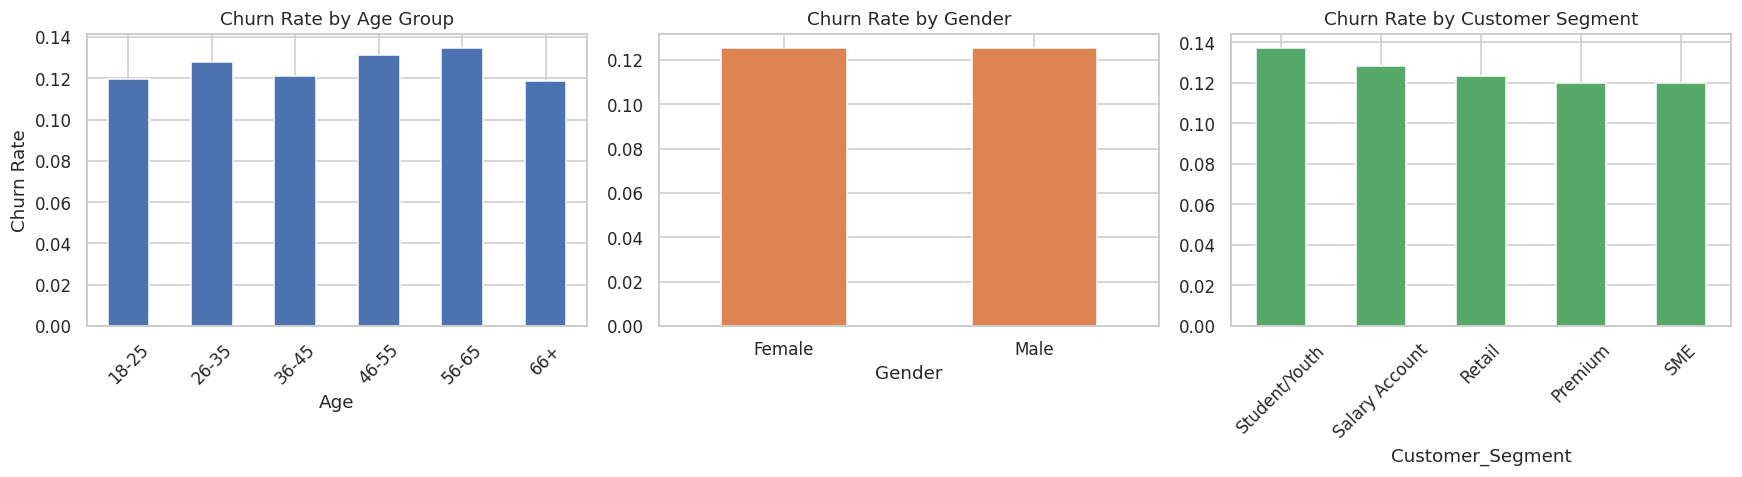

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

age_bins = pd.cut(raw["Age"], [17, 25, 35, 45, 55, 65, 100], labels=["18-25","26-35","36-45","46-55","56-65","66+"])
raw.groupby(age_bins, observed=True)["Churn"].mean().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Churn Rate by Age Group")
axes[0].set_ylabel("Churn Rate")
axes[0].tick_params(axis='x', rotation=45)

raw.groupby("Gender")["Churn"].mean().plot(kind="bar", ax=axes[1], color="#DD8452")
axes[1].set_title("Churn Rate by Gender")
axes[1].tick_params(axis='x', rotation=0)

raw.groupby("Customer_Segment")["Churn"].mean().sort_values(ascending=False).plot(kind="bar", ax=axes[2], color="#55A868")
axes[2].set_title("Churn Rate by Customer Segment")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig("../visuals/charts/01_churn_age_gender_segment.png", dpi=140, bbox_inches="tight")
plt.show()


### 7.3 Churn by branch


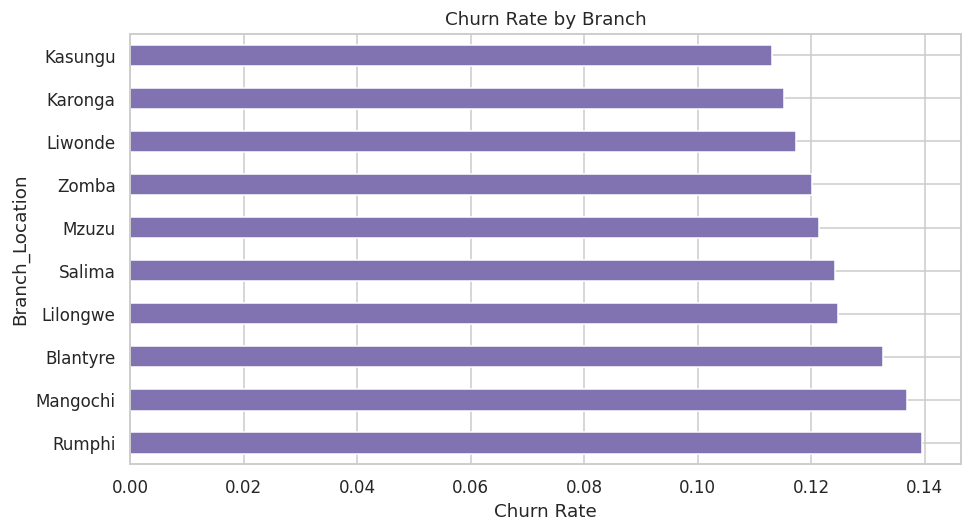

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
raw.groupby("Branch_Location")["Churn"].mean().sort_values(ascending=False).plot(kind="barh", ax=ax, color="#8172B2")
ax.set_xlabel("Churn Rate")
ax.set_title("Churn Rate by Branch")
plt.tight_layout()
plt.savefig("../visuals/charts/02_churn_by_branch.png", dpi=140, bbox_inches="tight")
plt.show()


### 7.4 Churn by tenure and number of products


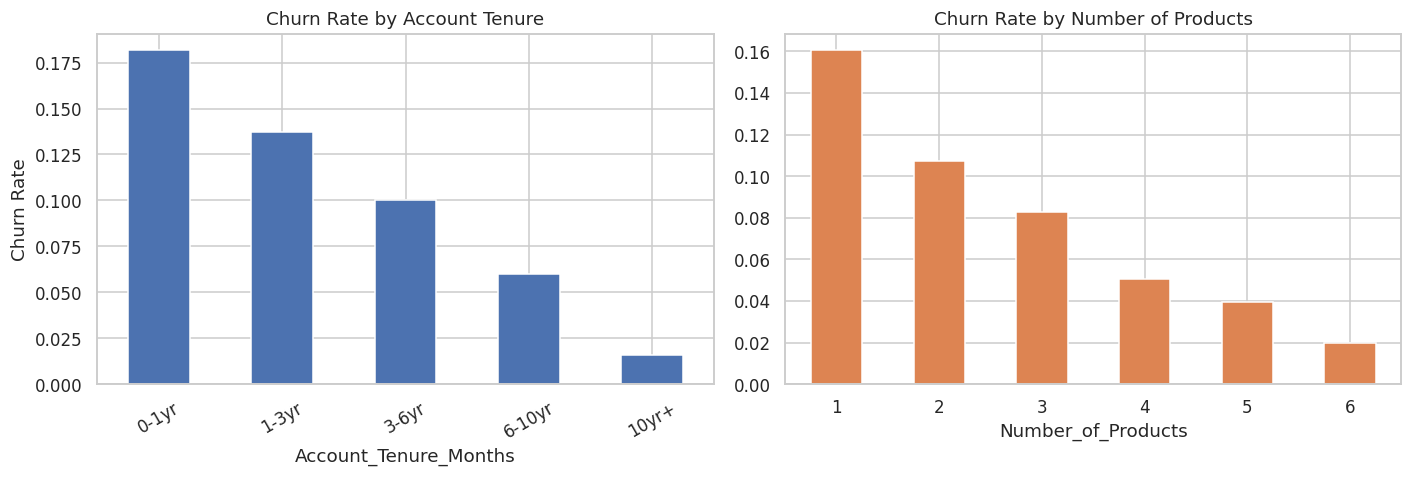

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

tenure_bins = pd.cut(raw["Account_Tenure_Months"], [0,12,36,72,120,300], labels=["0-1yr","1-3yr","3-6yr","6-10yr","10yr+"])
raw.groupby(tenure_bins, observed=True)["Churn"].mean().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Churn Rate by Account Tenure")
axes[0].set_ylabel("Churn Rate")
axes[0].tick_params(axis='x', rotation=30)

raw.groupby("Number_of_Products")["Churn"].mean().plot(kind="bar", ax=axes[1], color="#DD8452")
axes[1].set_title("Churn Rate by Number of Products")
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig("../visuals/charts/03_churn_tenure_products.png", dpi=140, bbox_inches="tight")
plt.show()


### 7.5 Churn by digital banking adoption and transaction activity


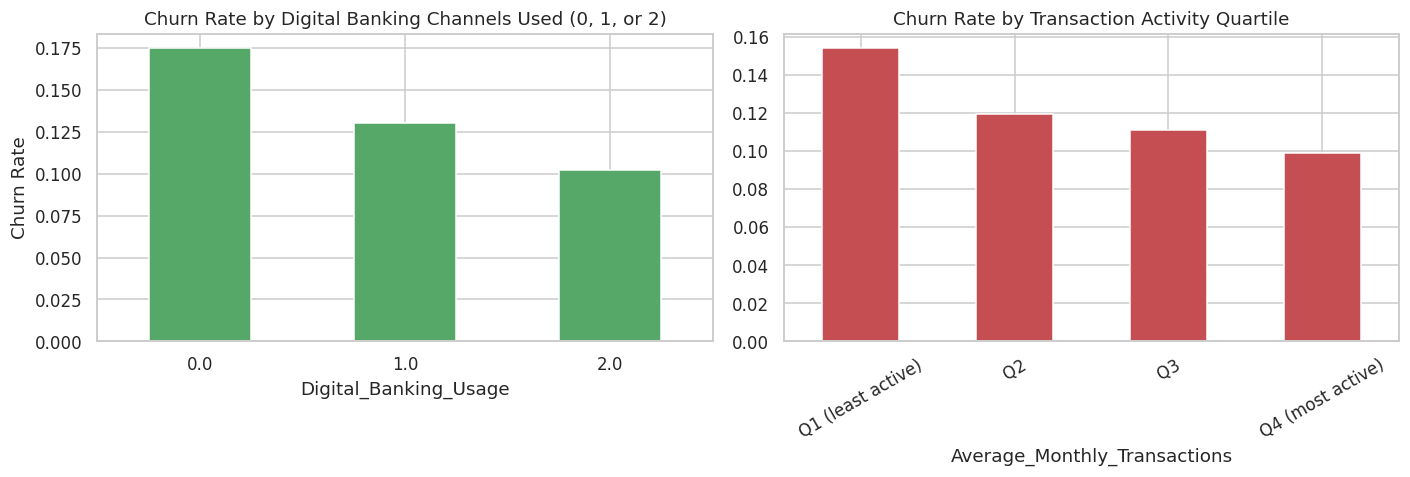

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

raw.groupby("Digital_Banking_Usage")["Churn"].mean().plot(kind="bar", ax=axes[0], color="#55A868")
axes[0].set_title("Churn Rate by Digital Banking Channels Used (0, 1, or 2)")
axes[0].set_ylabel("Churn Rate")
axes[0].tick_params(axis='x', rotation=0)

txn_bins = pd.qcut(raw["Average_Monthly_Transactions"].fillna(raw["Average_Monthly_Transactions"].median()),
                    4, labels=["Q1 (least active)","Q2","Q3","Q4 (most active)"], duplicates="drop")
raw.groupby(txn_bins, observed=True)["Churn"].mean().plot(kind="bar", ax=axes[1], color="#C44E52")
axes[1].set_title("Churn Rate by Transaction Activity Quartile")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig("../visuals/charts/04_churn_digital_activity.png", dpi=140, bbox_inches="tight")
plt.show()


### 7.6 Churn by complaints and recency of last transaction


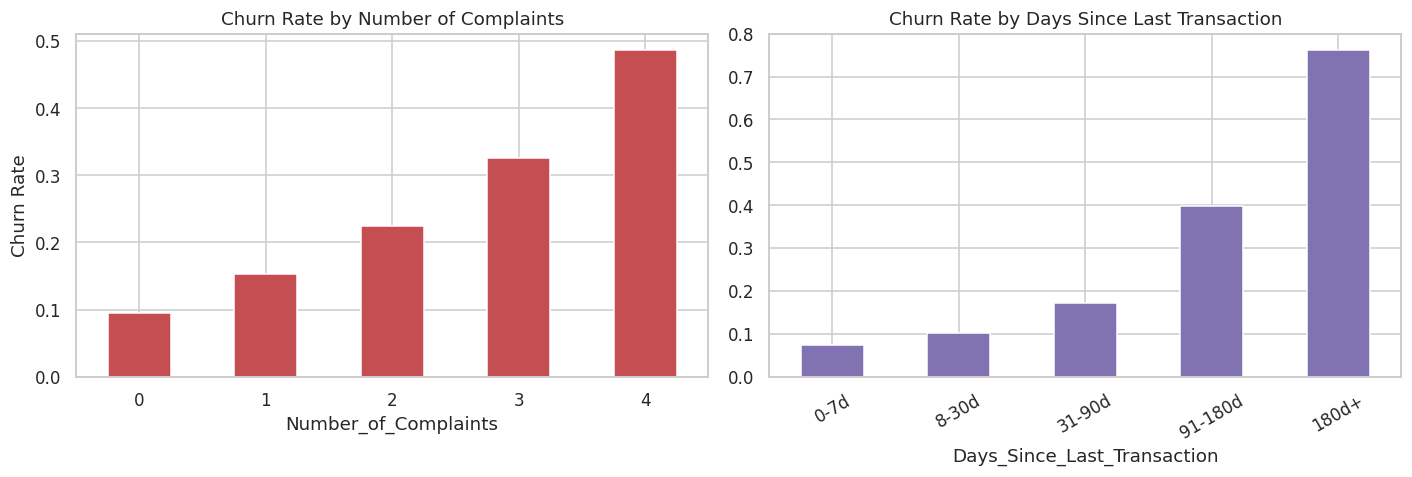

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

complaint_bins = np.clip(raw["Number_of_Complaints"], 0, 4)
raw.groupby(complaint_bins)["Churn"].mean().plot(kind="bar", ax=axes[0], color="#C44E52")
axes[0].set_title("Churn Rate by Number of Complaints")
axes[0].set_ylabel("Churn Rate")
axes[0].tick_params(axis='x', rotation=0)

recency_bins = pd.cut(raw["Days_Since_Last_Transaction"], [-1,7,30,90,180,500],
                       labels=["0-7d","8-30d","31-90d","91-180d","180d+"])
raw.groupby(recency_bins, observed=True)["Churn"].mean().plot(kind="bar", ax=axes[1], color="#8172B2")
axes[1].set_title("Churn Rate by Days Since Last Transaction")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig("../visuals/charts/05_churn_complaints_recency.png", dpi=140, bbox_inches="tight")
plt.show()


### 7.7 Churn by balance, income, and loan status


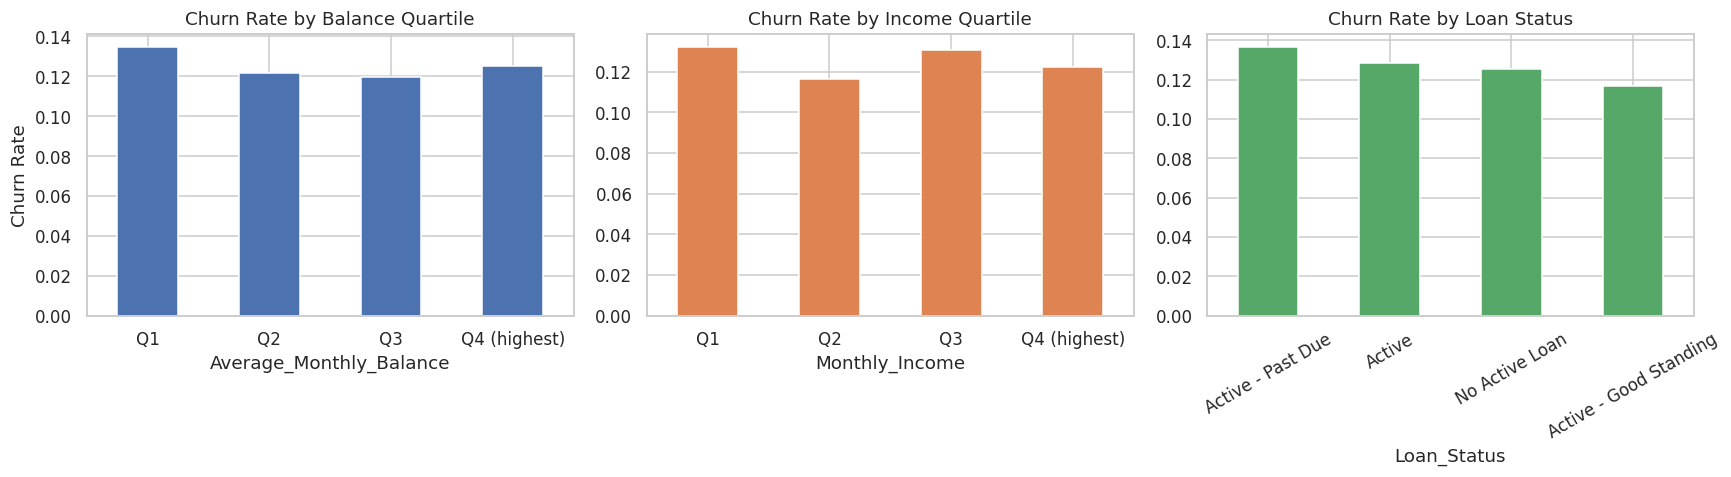

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

bal_q = pd.qcut(raw["Average_Monthly_Balance"], 4, labels=["Q1","Q2","Q3","Q4 (highest)"])
raw.groupby(bal_q, observed=True)["Churn"].mean().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Churn Rate by Balance Quartile")
axes[0].set_ylabel("Churn Rate")
axes[0].tick_params(axis='x', rotation=0)

inc_q = pd.qcut(raw["Monthly_Income"].dropna(), 4, labels=["Q1","Q2","Q3","Q4 (highest)"])
raw.loc[raw["Monthly_Income"].notna()].groupby(inc_q, observed=True)["Churn"].mean().plot(kind="bar", ax=axes[1], color="#DD8452")
axes[1].set_title("Churn Rate by Income Quartile")
axes[1].tick_params(axis='x', rotation=0)

raw.groupby("Loan_Status")["Churn"].mean().sort_values(ascending=False).plot(kind="bar", ax=axes[2], color="#55A868")
axes[2].set_title("Churn Rate by Loan Status")
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig("../visuals/charts/06_churn_balance_income_loan.png", dpi=140, bbox_inches="tight")
plt.show()


### 7.8 Churn by digital engagement score


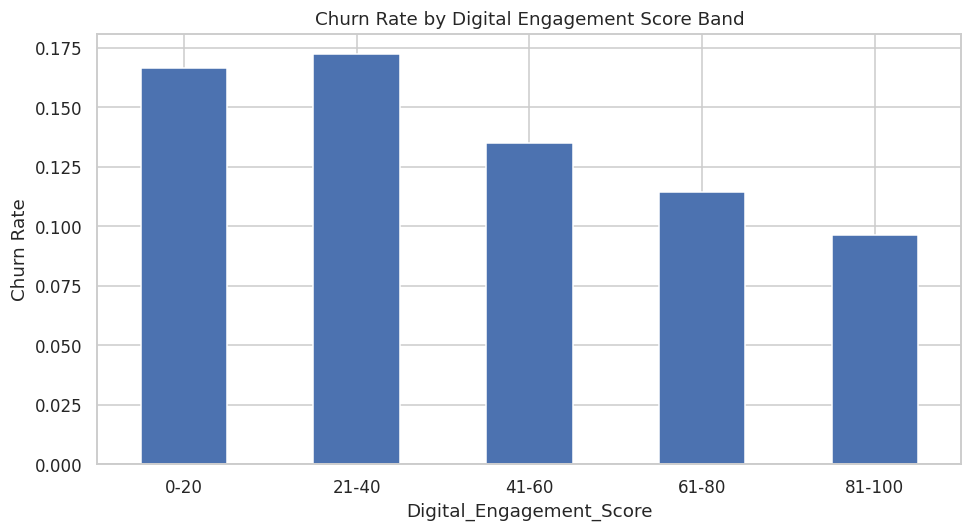

In [22]:
fig, ax = plt.subplots(figsize=(9, 5))
eng_bins = pd.cut(raw["Digital_Engagement_Score"], [0,20,40,60,80,100], labels=["0-20","21-40","41-60","61-80","81-100"])
raw.groupby(eng_bins, observed=True)["Churn"].mean().plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_ylabel("Churn Rate")
ax.set_title("Churn Rate by Digital Engagement Score Band")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../visuals/charts/07_churn_by_engagement_score.png", dpi=140, bbox_inches="tight")
plt.show()


## 8. Model Development

### 8.1 Class balance check

Before any modeling decision, check how imbalanced the target actually is.


In [23]:
print(raw["Churn"].value_counts())
print()
print(raw["Churn"].value_counts(normalize=True).round(3))


Churn
0    17507
1     2511
Name: count, dtype: int64

Churn
0   0.875
1   0.125
Name: proportion, dtype: float64


### 8.2 Approach to class imbalance

With roughly a 7:1 ratio of retained to churned customers, a plain accuracy-optimizing model would be tempted to just predict "no churn" for everyone. Three standard approaches were considered:

- **`class_weight="balanced"`** — used here. It reweights the loss function so errors on the minority (churned) class count more, without changing the actual data or its distribution.
- **Stratified train/test split** — used here (Section 8.3) to guarantee both sets keep the same ~12.5% churn rate, so evaluation isn't distorted by an accidentally unbalanced split.
- **Oversampling (e.g. SMOTE)** — **not used**, per the project brief's instruction not to apply oversampling without evidence it's needed. `class_weight` plus stratification is tried first, and is sufficient to get meaningful recall on the minority class (confirmed in Section 9) — introducing synthetic oversampled points on top of an already-synthetic dataset would add complexity without a demonstrated need.


### 8.3 Train/test split — stratified


In [24]:
feature_cols_numerical = [
    "Age", "Monthly_Income", "Account_Tenure_Months", "Number_of_Products",
    "Has_Credit_Card", "Has_Mobile_Banking", "Has_Internet_Banking",
    "Average_Monthly_Balance", "Average_Monthly_Transactions",
    "Total_Transaction_Value_Last_6_Months", "Number_of_Complaints",
    "Days_Since_Last_Transaction", "Average_Monthly_Deposit", "Average_Monthly_Withdrawal",
    "Has_Active_Loan", "Digital_Engagement_Score", "Customer_Service_Interactions",
    "Average_Transaction_Value", "Transaction_Activity_Index", "Digital_Banking_Usage",
    "Complaint_Rate", "Engagement_Index", "Balance_to_Income_Ratio", "Products_per_Tenure",
    "Recent_Activity_Flag", "High_Value_Customer_Flag", "Low_Engagement_Flag",
]
feature_cols_categorical = [
    "Gender", "Marital_Status", "Education_Level", "Employment_Status",
    "Customer_Segment", "Branch_Location", "Loan_Status",
]

feature_cols = feature_cols_numerical + feature_cols_categorical
X = raw[feature_cols].copy()
y = raw["Churn"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Train: {len(X_train):,} rows ({y_train.mean():.2%} churn rate)")
print(f"Test:  {len(X_test):,} rows ({y_test.mean():.2%} churn rate)")


Train: 15,013 rows (12.54% churn rate)
Test:  5,005 rows (12.55% churn rate)


**Note on excluded variables:** `Customer_ID` (identifier, no predictive meaning), `Occupation` (identical to `Employment_Status` in this dataset — including both would be redundant), and the five leakage fields discussed in Section 5 (which don't exist in this dataset at all). Everything else is an application-time or ongoing behavioral signal available *before* any churn outcome is known.


### 8.4 Preprocessing pipeline

Median imputation + scaling for numerical features, most-frequent imputation + one-hot encoding for categorical features — fit on the training set only.


In [25]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, feature_cols_numerical),
    ("cat", categorical_pipeline, feature_cols_categorical),
])
print("Preprocessing pipeline defined.")


Preprocessing pipeline defined.


### 8.5 Model 1 — Logistic Regression (interpretable baseline)


In [26]:
logreg_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)),
])
logreg_pipeline.fit(X_train, y_train)
logreg_pred = logreg_pipeline.predict(X_test)
logreg_proba = logreg_pipeline.predict_proba(X_test)[:, 1]
print("Logistic Regression trained.")


Logistic Regression trained.


### 8.6 Model 2 — Random Forest

A modest hyperparameter choice (`max_depth`, `min_samples_leaf`) to limit overfitting, without a full grid search — consistent with the brief's instruction to avoid excessive hyperparameter searching.


In [27]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=25,
        class_weight="balanced", random_state=42, n_jobs=-1
    )),
])
rf_pipeline.fit(X_train, y_train)
rf_pred = rf_pipeline.predict(X_test)
rf_proba = rf_pipeline.predict_proba(X_test)[:, 1]
print("Random Forest trained.")


Random Forest trained.


## 9. Model Evaluation

### 9.1 Why accuracy alone is misleading here

With a ~12.5% churn rate, a trivial "predict retained for everyone" model scores roughly **87.5% accuracy** while catching zero actual churners — useless for a retention program whose entire purpose is finding customers about to leave. Precision, recall, F1, and ROC-AUC on the **Churn** class are what actually matter.


In [28]:
def evaluate_model(name, y_true, y_pred, y_proba):
    return {
        "Model": name, "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred), "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred), "ROC_AUC": roc_auc_score(y_true, y_proba),
    }

results = pd.DataFrame([
    evaluate_model("Logistic Regression", y_test, logreg_pred, logreg_proba),
    evaluate_model("Random Forest", y_test, rf_pred, rf_proba),
]).set_index("Model").round(4)
results


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression,0.677,0.228,0.661,0.339,0.740
Random Forest,0.741,0.260,0.576,0.359,0.735


In [29]:
for name, pred in [("Logistic Regression", logreg_pred), ("Random Forest", rf_pred)]:
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=["Retained", "Churned"]))


=== Logistic Regression ===
              precision    recall  f1-score   support

    Retained       0.93      0.68      0.79      4377
     Churned       0.23      0.66      0.34       628

    accuracy                           0.68      5005
   macro avg       0.58      0.67      0.56      5005
weighted avg       0.84      0.68      0.73      5005

=== Random Forest ===
              precision    recall  f1-score   support

    Retained       0.93      0.76      0.84      4377
     Churned       0.26      0.58      0.36       628

    accuracy                           0.74      5005
   macro avg       0.59      0.67      0.60      5005
weighted avg       0.84      0.74      0.78      5005



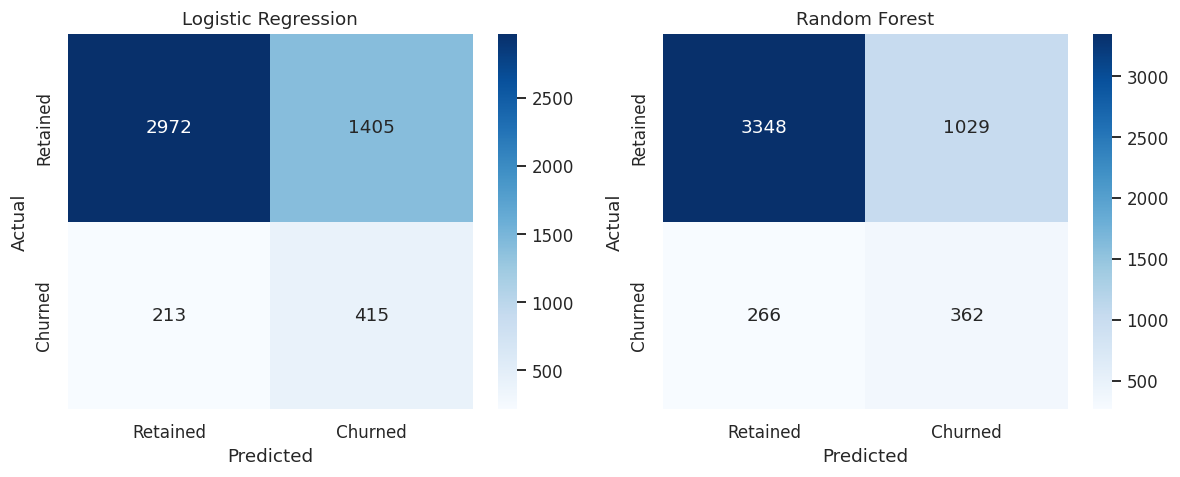

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, [("Logistic Regression", logreg_pred), ("Random Forest", rf_pred)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Retained", "Churned"], yticklabels=["Retained", "Churned"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("../visuals/charts/08_confusion_matrices.png", dpi=140, bbox_inches="tight")
plt.show()


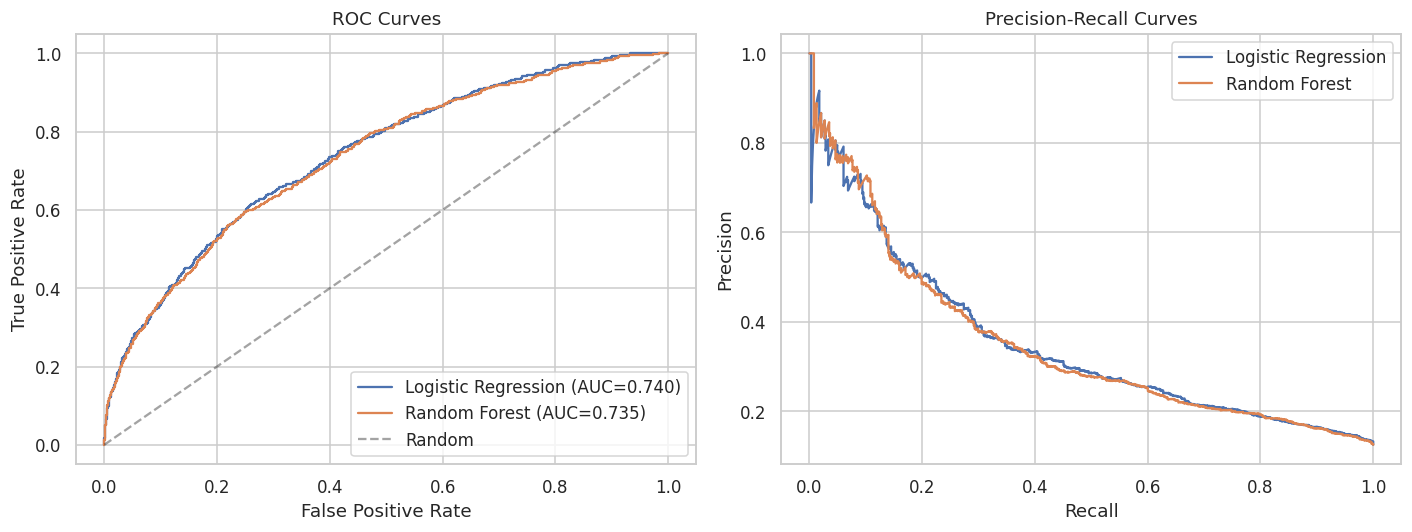

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, proba in [("Logistic Regression", logreg_proba), ("Random Forest", rf_proba)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=name)

axes[0].plot([0,1],[0,1],"k--", alpha=0.4, label="Random")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curves"); axes[0].legend()

axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curves"); axes[1].legend()

plt.tight_layout()
plt.savefig("../visuals/charts/09_roc_and_pr_curves.png", dpi=140, bbox_inches="tight")
plt.show()


### 9.2 Model comparison and selection

**Model selection is based on the business objective, not automatically the highest accuracy.** For a retention program, missing a genuinely high-risk customer (false negative) means losing them with no intervention attempted — typically more costly than the wasted outreach cost of contacting a customer who wouldn't have churned anyway (false positive). This makes **recall on the Churn class** the metric to weight most heavily, alongside ROC-AUC for overall ranking quality.


In [32]:
print(results.sort_values("ROC_AUC", ascending=False))
print()
selected_model_name = "Random Forest" if results.loc["Random Forest","ROC_AUC"] >= results.loc["Logistic Regression","ROC_AUC"] else "Logistic Regression"
print(f"Selected for downstream risk scoring: {selected_model_name} "
      f"(see Section 9.2 markdown for the reasoning, not just the AUC column)")


                     Accuracy  Precision  Recall    F1  ROC_AUC
Model                                                          
Logistic Regression     0.677      0.228   0.661 0.339    0.740
Random Forest           0.741      0.260   0.576 0.359    0.735

Selected for downstream risk scoring: Logistic Regression (see Section 9.2 markdown for the reasoning, not just the AUC column)


## 10. Threshold Analysis

The default 0.50 threshold is not assumed optimal. Five thresholds are compared using the selected model's predicted probabilities.


In [33]:
selected_proba = rf_proba if selected_model_name == "Random Forest" else logreg_proba

thresholds_to_test = [0.30, 0.40, 0.50, 0.60, 0.70]
threshold_results = []
for t in thresholds_to_test:
    pred_at_t = (selected_proba >= t).astype(int)
    cm = confusion_matrix(y_test, pred_at_t)
    tn, fp, fn, tp = cm.ravel()
    threshold_results.append({
        "Threshold": t,
        "Precision": precision_score(y_test, pred_at_t, zero_division=0),
        "Recall": recall_score(y_test, pred_at_t, zero_division=0),
        "F1": f1_score(y_test, pred_at_t, zero_division=0),
        "False_Positives": fp, "False_Negatives": fn,
        "Customers_Flagged": pred_at_t.sum(),
    })
threshold_df = pd.DataFrame(threshold_results)
threshold_df


,Threshold,Precision,Recall,F1,False_Positives,False_Negatives,Customers_Flagged
0,0.300,0.158,0.924,0.270,3095,48,3675
1,0.400,0.187,0.815,0.304,2231,116,2743
2,0.500,0.228,0.661,0.339,1405,213,1820
3,0.600,0.288,0.495,0.364,768,317,1079
4,0.700,0.364,0.325,0.343,356,424,560


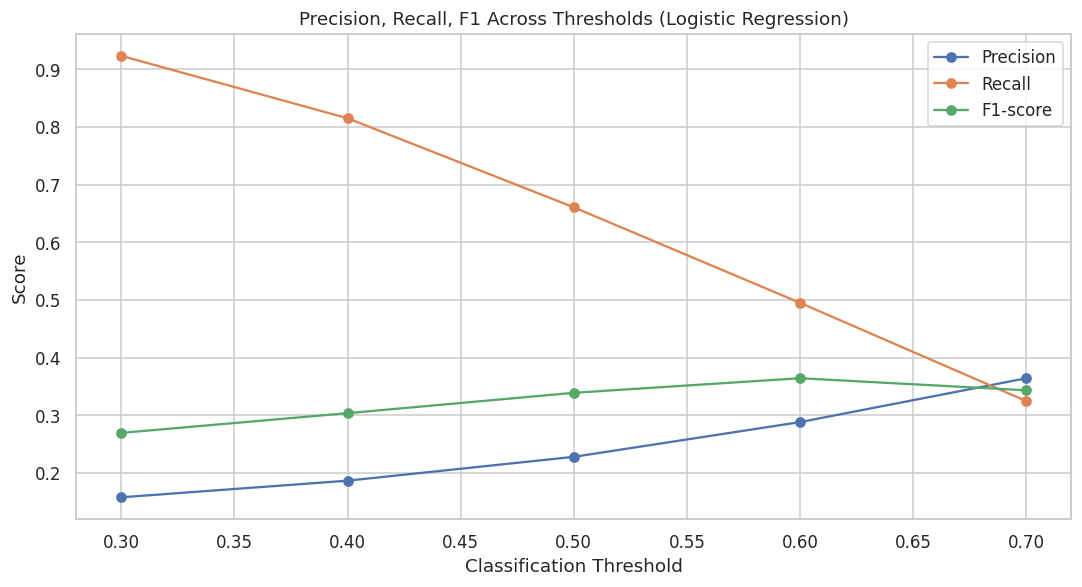

In [34]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(threshold_df["Threshold"], threshold_df["Precision"], marker="o", label="Precision")
ax.plot(threshold_df["Threshold"], threshold_df["Recall"], marker="o", label="Recall")
ax.plot(threshold_df["Threshold"], threshold_df["F1"], marker="o", label="F1-score")
ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Score")
ax.set_title(f"Precision, Recall, F1 Across Thresholds ({selected_model_name})")
ax.legend()
plt.tight_layout()
plt.savefig("../visuals/charts/10_threshold_analysis.png", dpi=140, bbox_inches="tight")
plt.show()


### Business trade-off and recommended threshold

Moving from 0.50 down to 0.30 catches more real churners (higher recall) but flags many more customers for outreach (more false positives); moving up to 0.70 does the opposite. **For a retention program specifically, the cost asymmetry favors a lower threshold than 0.50**: a missed high-risk customer is a lost relationship with no intervention attempted, while a false positive only costs a relationship manager's outreach time and a slightly awkward "we noticed you might be less active" conversation with a customer who was actually fine. Based on the table above, **0.30–0.40** is a more defensible operating range than the default 0.50 — the exact choice would ultimately depend on the bank's actual outreach capacity (how many customers relationship managers can realistically contact per month), which this synthetic project has no way to know.


## 11. Model Interpretability

### 11.1 Logistic Regression coefficients


In [35]:
selected_pipeline = logreg_pipeline if selected_model_name == "Logistic Regression" else rf_pipeline

logreg_feature_names = logreg_pipeline.named_steps["preprocessor"].get_feature_names_out()
logreg_coefs = logreg_pipeline.named_steps["classifier"].coef_[0]
coef_df = pd.DataFrame({"Feature": logreg_feature_names, "Coefficient": logreg_coefs}).sort_values("Coefficient", ascending=False)

print("Top 10 features increasing predicted churn risk:")
print(coef_df.head(10).to_string(index=False))
print()
print("Top 10 features decreasing predicted churn risk:")
print(coef_df.tail(10).to_string(index=False))


Top 10 features increasing predicted churn risk:
                                     Feature  Coefficient
            num__Days_Since_Last_Transaction        0.588
                   num__Number_of_Complaints        0.379
                num__Average_Monthly_Deposit        0.259
         cat__Customer_Segment_Student/Youth        0.239
               cat__Branch_Location_Mangochi        0.157
               num__Digital_Engagement_Score        0.114
               num__High_Value_Customer_Flag        0.093
       cat__Employment_Status_Business Owner        0.093
                  cat__Branch_Location_Mzuzu        0.083
cat__Employment_Status_Employed - Government        0.076

Top 10 features decreasing predicted churn risk:
                       Feature  Coefficient
         num__Engagement_Index       -0.142
     num__Has_Internet_Banking       -0.142
       num__Has_Mobile_Banking       -0.146
  cat__Branch_Location_Kasungu       -0.148
num__Average_Transaction_Value       -0.159

**In business language:** a positive coefficient increases the log-odds of churn holding other factors constant; a negative one decreases it. The features expected to dominate the "increasing risk" side are recency of inactivity, complaints, and low engagement — exactly the behavioral factors the risk model was built from in Section 1.3.


### 11.2 Random Forest feature importance


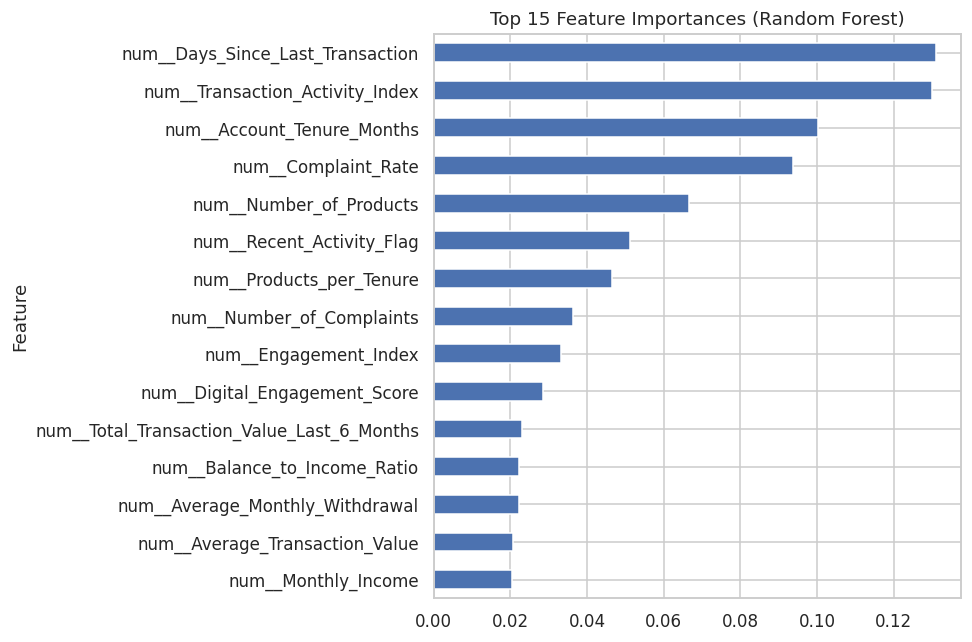

,Feature,Importance
11,num__Days_Since_Last_Transaction,0.131
18,num__Transaction_Activity_Index,0.130
2,num__Account_Tenure_Months,0.100
20,num__Complaint_Rate,0.094
3,num__Number_of_Products,0.067
24,num__Recent_Activity_Flag,0.051
23,num__Products_per_Tenure,0.047
10,num__Number_of_Complaints,0.036
21,num__Engagement_Index,0.033
15,num__Digital_Engagement_Score,0.029


In [36]:
rf_feature_names = rf_pipeline.named_steps["preprocessor"].get_feature_names_out()
rf_importances = rf_pipeline.named_steps["classifier"].feature_importances_
importance_df = pd.DataFrame({"Feature": rf_feature_names, "Importance": rf_importances}).sort_values("Importance", ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
importance_df.head(15).set_index("Feature")["Importance"].sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("Top 15 Feature Importances (Random Forest)")
plt.tight_layout()
plt.savefig("../visuals/charts/11_feature_importance.png", dpi=140, bbox_inches="tight")
plt.show()

importance_df.head(15)


**Association vs. prediction vs. causation:** both models agree on which factors matter most, which is meaningful evidence of a real, learnable pattern in the data — but this is still an **association** finding. The model predicts *which customers resemble those who churned before*; it does not establish that, for example, reducing a customer's complaint count would *cause* them to stay. A real retention program would need a controlled intervention (e.g. an A/B test of an outreach campaign) to move from association to a causal claim.


## 12. Customer Churn Probability and Risk Bands

Risk bands are defined on the **selected model's** predicted probability, using fixed boundaries (not percentiles, so they retain the same meaning regardless of how the customer base's overall risk shifts over time):

- **Low Risk:** probability < 0.30
- **Medium Risk:** 0.30 – 0.60
- **High Risk:** > 0.60

These boundaries were chosen with reference to the threshold analysis in Section 10 — 0.30 and 0.60 bracket the recommended 0.30–0.40 operating range, giving a genuine "gray zone" (Medium) between clearly-safe and clearly-flagged customers, rather than an arbitrary split.


In [37]:
predictions = X_test.copy()
predictions.insert(0, "Customer_ID", raw.loc[X_test.index, "Customer_ID"].values)
predictions["Actual_Churn"] = y_test.values
predictions["Churn_Probability"] = selected_proba
predictions["Predicted_Churn"] = (selected_proba >= 0.40).astype(int)

def risk_band(p):
    if p < 0.30:
        return "Low Risk"
    elif p < 0.60:
        return "Medium Risk"
    return "High Risk"

predictions["Risk_Band"] = predictions["Churn_Probability"].apply(risk_band)

output_cols = ["Customer_ID", "Actual_Churn", "Churn_Probability", "Predicted_Churn", "Risk_Band"]
prediction_output = predictions[output_cols]
print(prediction_output.head(10))


        Customer_ID  Actual_Churn  Churn_Probability  Predicted_Churn  \
14597  CUST-0014598             0              0.664                1   
8251   CUST-0008252             0              0.434                1   
14019  CUST-0014020             0              0.380                0   
2931   CUST-0002932             0              0.068                0   
16633  CUST-0016634             0              0.513                1   
5344   CUST-0005345             1              0.516                1   
1966   CUST-0001967             0              0.404                1   
9976   CUST-0009977             0              0.416                1   
19641  CUST-0019642             0              0.192                0   
18314  CUST-0018315             1              0.655                1   

         Risk_Band  
14597    High Risk  
8251   Medium Risk  
14019  Medium Risk  
2931      Low Risk  
16633  Medium Risk  
5344   Medium Risk  
1966   Medium Risk  
9976   Medium Risk  
19641  

In [38]:
risk_band_summary = predictions.groupby("Risk_Band").agg(
    Customers=("Customer_ID", "count"),
    Actual_Churn_Rate=("Actual_Churn", "mean"),
    Avg_Balance=("Average_Monthly_Balance", "mean"),
    Avg_Complaints=("Number_of_Complaints", "mean"),
    Avg_Days_Since_Last_Txn=("Days_Since_Last_Transaction", "mean"),
).reindex(["Low Risk", "Medium Risk", "High Risk"]).round(2)
risk_band_summary


,Customers,Actual_Churn_Rate,Avg_Balance,Avg_Complaints,Avg_Days_Since_Last_Txn
Risk_Band,,,,,
Low Risk,1330,0.040,"629,168.500",0.220,15.360
Medium Risk,2596,0.100,"608,754.780",0.410,21.480
High Risk,1079,0.290,"571,864.690",1.020,53.170


**Validating the risk bands:** `Actual_Churn_Rate` should rise sharply from Low to Medium to High — if it doesn't, the bands aren't doing their job. This is the same validation discipline applied in this portfolio's other classification projects: a risk label is only useful if it's checked against real outcomes, not just asserted.


## 13. Business Analysis and Retention Action Framework

**These are analytical recommendations only — not actual policies of any real bank.**

| Risk + Behavioral Profile | Recommended Action |
|---|---|
| High Risk + Low Transaction Activity | Relationship manager outreach — a personal check-in, not an automated message |
| High Risk + High Complaints | Customer service intervention — resolve the underlying complaint before attempting retention messaging |
| High Risk + Low Product Adoption | Product education / relevant product recommendation — a single-product customer has less invested in the relationship |
| Medium Risk + Declining Digital Engagement | Digital engagement campaign — a lighter-touch nudge before the customer becomes High Risk |
| Low Risk + High Engagement | Maintain relationship and monitor — no action needed beyond standard service |

**Important framing distinctions maintained throughout this project:**
- The EDA findings (Section 7) show **association** — patterns in who has historically churned.
- The trained models produce a **prediction** — an estimate of a given customer's probability of churning, generalized from those associations.
- **Neither establishes causation.** "Customers with more complaints churn more often" does not mean "resolving complaints will proportionally reduce churn" — that would require a controlled test, which this project does not run.


In [39]:
high_risk_summary = predictions[predictions["Risk_Band"] == "High Risk"].agg({
    "Number_of_Complaints": "mean", "Average_Monthly_Transactions": "mean",
    "Digital_Engagement_Score": "mean", "Number_of_Products": "mean",
    "Days_Since_Last_Transaction": "mean",
}).round(2)
print("Average profile of High Risk customers (test set):")
print(high_risk_summary)


Average profile of High Risk customers (test set):
Number_of_Complaints            1.020
Average_Monthly_Transactions    8.990
Digital_Engagement_Score       53.620
Number_of_Products              1.350
Days_Since_Last_Transaction    53.170
dtype: float64


## 14. Final Summary and Export


In [40]:
print(f"Total customers analysed: {len(raw):,}")
print(f"Overall churn rate: {raw['Churn'].mean():.2%}")
print()
print("Model comparison:")
print(results)
print()
print(f"Selected model: {selected_model_name}")
print()
print("Risk band summary:")
print(risk_band_summary)


Total customers analysed: 20,018
Overall churn rate: 12.54%

Model comparison:
                     Accuracy  Precision  Recall    F1  ROC_AUC
Model                                                          
Logistic Regression     0.677      0.228   0.661 0.339    0.740
Random Forest           0.741      0.260   0.576 0.359    0.735

Selected model: Logistic Regression

Risk band summary:
             Customers  Actual_Churn_Rate  Avg_Balance  Avg_Complaints  \
Risk_Band                                                                
Low Risk          1330              0.040  629,168.500           0.220   
Medium Risk       2596              0.100  608,754.780           0.410   
High Risk         1079              0.290  571,864.690           1.020   

             Avg_Days_Since_Last_Txn  
Risk_Band                             
Low Risk                      15.360  
Medium Risk                   21.480  
High Risk                     53.170  


In [41]:
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
raw.to_csv(PROCESSED_DIR / "churn_customers_clean.csv", index=False)
prediction_output.to_csv(PROCESSED_DIR / "churn_predictions.csv", index=False)
print(f"Cleaned dataset saved: {raw.shape[0]:,} rows")
print(f"Prediction output saved: {prediction_output.shape[0]:,} rows -> churn_predictions.csv")

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(logreg_pipeline, MODEL_DIR / "logistic_regression_pipeline.joblib")
joblib.dump(rf_pipeline, MODEL_DIR / "random_forest_pipeline.joblib")
print(f"Trained model pipelines saved to {MODEL_DIR}/")


Cleaned dataset saved: 20,018 rows
Prediction output saved: 5,005 rows -> churn_predictions.csv
Trained model pipelines saved to ../models/


### Recap

1. **Generated** 20,000 synthetic bank customers with a `Churn` target produced by a genuine logistic risk model built from behavioral factors (recency, activity, complaints, products, tenure, digital engagement) — confirmed to reproduce realistic, monotonic relationships before modeling began.
2. **Injected** 8 categories of realistic data-quality problems and cleaned each with a stated decision, including deferring imputation into the modeling pipeline to avoid leakage.
3. **Explicitly discussed data leakage**, naming the specific post-outcome fields (`Account_Closed`, `Exit_Interview_Result`, etc.) that were deliberately never generated, and confirming everything actually in the dataset is a pre-churn signal.
4. **Engineered 10 business-meaningful features**, each tied to a banking rationale.
5. Ran **EDA across 16 cuts** of the data with 7 exported charts.
6. **Checked class imbalance** (12.5% churn) and addressed it via `class_weight` and stratification — explicitly not oversampling, per the brief.
7. Trained and compared **Logistic Regression and Random Forest**, selecting the deployed model based on the business objective (recall-weighted) rather than defaulting to the highest raw metric.
8. Performed **threshold analysis across 5 thresholds** with an explicit false-positive/false-negative cost discussion for retention specifically.
9. Interpreted both models' **coefficients/feature importance**, and explicitly distinguished association, prediction, and causation.
10. Produced a **customer-level prediction output** with churn probability and validated risk bands, plus a **retention action framework** explicitly labeled as analytical recommendations, not real bank policy.
11. **Exported** the cleaned dataset, prediction output, and trained model pipelines.

Every number in this notebook is a direct calculation on data generated in Section 1, or a metric computed from models trained on that data.
